# scRICH workflow on scRNA-seq dataset

This tutorial shows the main analysis and visualizations proivided by scRICH to identify rubust cell-cell communication modes from scRNA-seq data.

General considerations for plotting:

all plotting functions generate matplotlib-based figures that can be exported. The following optional arguments control whether figures are shown and saved, the figure name (including path to a directory, and format):

showfig (default=False): if True, the figure is displayed.
savefig (default=True): if True, the figure is exported using plt.savefig().
figname (default=a descriptive name + 'pdf').
format (default='pdf').

In this notebook, all plotting functions are explicitly set to *savefig=False*, *showfig=True*.

### 0-Preprocessing and input data

For this tutorial, we consider a blood differentiation dataset that is directly accessible through scvelo. We download the dataset and run preprocessing and RNA velocity calculation following scvelo's [tutorial](https://scvelo.readthedocs.io/en/stable/index.html). 

First, required libraries are loaded.

In [2]:
import scvelo as scv
import scanpy as sc
import os
import string
import matplotlib.pyplot as plt

%load_ext autoreload
%autoreload 2
import scrich as ri

In [3]:
import warnings
warnings.simplefilter("ignore", DeprecationWarning)

This dataset includes 9815 cells from 5 blood cell types that were already annotated.

In [4]:
adata = scv.datasets.gastrulation_erythroid()

In [5]:
print(adata)

AnnData object with n_obs × n_vars = 9815 × 53801
    obs: 'sample', 'stage', 'sequencing.batch', 'theiler', 'celltype'
    var: 'Accession', 'Chromosome', 'End', 'Start', 'Strand', 'MURK_gene', 'Δm', 'scaled Δm'
    uns: 'celltype_colors'
    obsm: 'X_pca', 'X_umap'
    layers: 'spliced', 'unspliced'


First, we normalize the data and compute moments following scVelo's approach.

In [6]:
scv.pp.filter_and_normalize(adata, min_shared_counts=20)
scv.pp.moments(adata, n_pcs=30, n_neighbors=30)

Filtered out 47456 genes that are detected 20 counts (shared).
Normalized count data: X, spliced, unspliced.
Logarithmized X.
computing neighbors


/Users/federicobocci/Desktop/commflow_project/ccc_project/commflow_env/lib/python3.9/site-packages/scvelo/preprocessing/utils.py:705: DeprecationWarning: `log1p` is deprecated since scVelo v0.3.0 and will be removed in a future version. Please use `log1p` from `scanpy.pp` instead.
  log1p(adata)
/var/folders/h8/221dz5dn3t7fnjtc80l_3p7c0000gn/T/ipykernel_7724/3097972183.py:2: DeprecationWarning: Automatic neighbor calculation is deprecated since scvelo==0.4.0 and will be removed in a future version of scVelo. Please compute neighbors first with Scanpy.
  scv.pp.moments(adata, n_pcs=30, n_neighbors=30)
/Users/federicobocci/Desktop/commflow_project/ccc_project/commflow_env/lib/python3.9/site-packages/scvelo/preprocessing/moments.py:71: DeprecationWarning: `neighbors` is deprecated since scvelo==0.4.0 and will be removed in a future version of scVelo. Please compute neighbors with Scanpy.
  neighbors(


    finished (0:00:08) --> added 
    'distances' and 'connectivities', weighted adjacency matrices (adata.obsp)
computing moments based on connectivities
    finished (0:00:02) --> added 
    'Ms' and 'Mu', moments of un/spliced abundances (adata.layers)


/Users/federicobocci/Desktop/commflow_project/ccc_project/commflow_env/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:163: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = copy(get_cmap(cmap))
/Users/federicobocci/Desktop/commflow_project/ccc_project/commflow_env/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:1208: DeprecationWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, pd.CategoricalDtype) instead
  if not is_categorical_dtype(values):


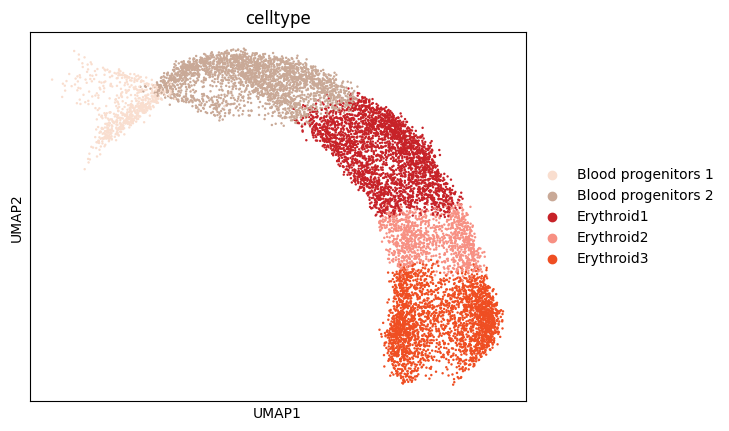

In [7]:
sc.pl.umap(adata, color='celltype')

### 1-Identification of main CCC pathways in the dataset

The cf.tl.pathways_overview command quantifies the strenght of each CCC pathway in the dataset based on either (1) overall expression of ligands and receptors in the pathway or (2) overall number of ligands/receptors that are detected in the pathway. The result of ths overview can be visualized with the cf.pl.pathways_overview command. This analysis is useful to set a cutoff for how many pathways are considered in the follow-up analysis.

In [8]:
ri.tl.rename_cells(adata, {'Blood progenitors 1': 'BP-1', 'Blood progenitors 2': 'BP-2', 'Erythroid1': 'Er-1', 'Erythroid2': 'Er-2', 'Erythroid3': 'Er-3'}, key='celltype')

In [9]:
ri.tl.pathways_overview(adata, human=False)

Scanning for cell-cell communication pathways...
Identified 11 pathways with at least one Receptor and one Ligand detected


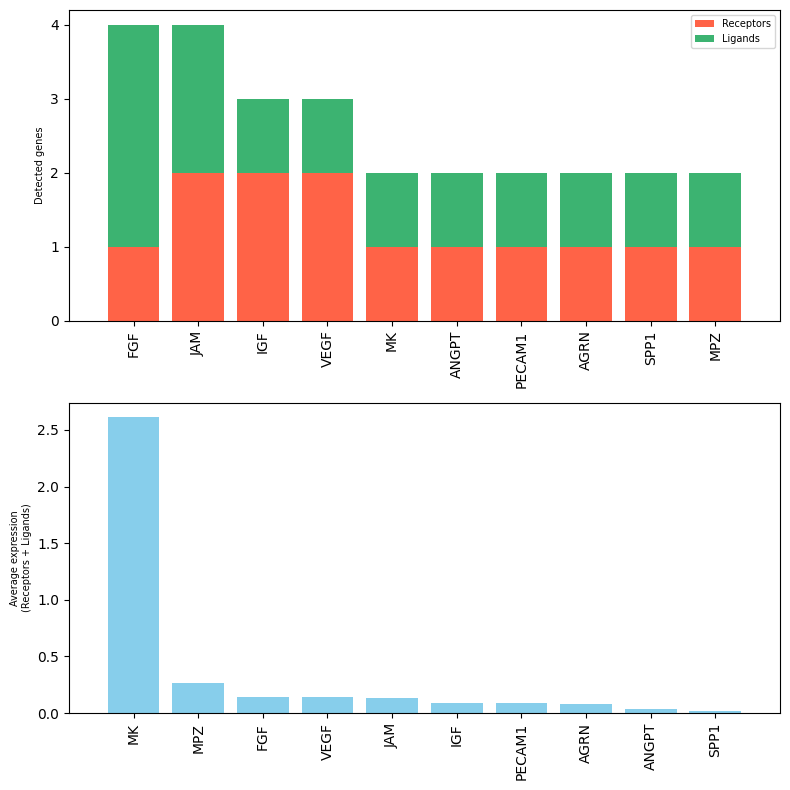

In [10]:
ri.pl.pathways_overview(adata, top=10, ticksize=10, savefig=False, showfig=True)

The new information about the CCC pathways is stored in *adata.uns['paths_overview']*, and includes the number and average expression of ligands and receptors for each CCC pathway:

In [11]:
adata.uns['paths_overview']

{'gene_number': {'JAM': [2, 2],
  'VEGF': [2, 1],
  'CADM': [1, 1],
  'MPZ': [1, 1],
  'SPP1': [1, 1],
  'FGF': [1, 3],
  'AGRN': [1, 1],
  'IGF': [2, 1],
  'PECAM1': [1, 1],
  'ANGPT': [1, 1],
  'MK': [1, 1]},
 'gene_expression': {'JAM': [0.13382415, 0.13382415],
  'VEGF': [0.04340251, 0.23631749],
  'CADM': [0.01156609, 0.01156609],
  'MPZ': [0.26533732, 0.26533732],
  'SPP1': [0.0318167, 0.0034978548],
  'FGF': [0.033648547, 0.24665096],
  'AGRN': [0.06758421, 0.09421572],
  'IGF': [0.15478638, 0.0300973],
  'PECAM1': [0.08691501, 0.08691501],
  'ANGPT': [0.07597682, 0.0027961396],
  'MK': [3.2685761, 1.9552737]}}

### 2-Detailed exploration of a CCC pathway

Now, we show how to investigate in more detail the behavior of a specific CCC pathway, using the example of IGF. First, we identify the number of IGF CCC signaling modes based on scRICH's nonnegative matrix factorization-based (NMF) clustering:

In [12]:
ri.tl.all_path_sim(adata, 'celltype', method='expression', pathways_to_use=['IGF'], target=False, human=False,
                       neighbor_average=True, print_info=True)

['IGF']
Analyzing the IGF pathway...
running clustering
Running clustering with nsim=5, kmin=3, kmax=6
clustering #1 with k=3
clustering #2 with k=3
clustering #3 with k=3
clustering #4 with k=3
clustering #5 with k=3
clustering #1 with k=4
clustering #2 with k=4
clustering #3 with k=4
clustering #4 with k=4
clustering #5 with k=4
clustering #1 with k=5
clustering #2 with k=5
clustering #3 with k=5
clustering #4 with k=5
clustering #5 with k=5
clustering #1 with k=6
clustering #2 with k=6
clustering #3 with k=6
clustering #4 with k=6
clustering #5 with k=6
finished sim_mat for IGF, starting spectral analysis

The optimal number of clusters is 3
running consensus
dict_keys(['celltype_colors', 'log1p', 'neighbors', 'pathways', 'paths_overview', 'selected_pathways', 'SymNMF', 'fraction_mat']) 4


The clustering identifies 3 IGF CCC modes. We further perform permutation testing to identify cell types that will be functionally sepaarted between these distinct IGF CCC modes. 

In [13]:
ri.tl.permutation_testing(adata, key='celltype')

New information about the CCC pathway is stored in different entries of *adata.uns*, including:
* the heterogeneity scores of cell types
* the smallest eigenvalues of the pathway similarity matrix
* the decomposition of cell types in CCC signaling modes (number of cells)
* the p-values for permutation test

In [14]:
adata

AnnData object with n_obs × n_vars = 9815 × 6345
    obs: 'sample', 'stage', 'sequencing.batch', 'theiler', 'celltype', 'initial_size_unspliced', 'initial_size_spliced', 'initial_size', 'n_counts', 'IGF_rec', 'IGF_lig', 'IGF_modes'
    var: 'Accession', 'Chromosome', 'End', 'Start', 'Strand', 'MURK_gene', 'Δm', 'scaled Δm', 'gene_count_corr'
    uns: 'celltype_colors', 'log1p', 'neighbors', 'pathways', 'paths_overview', 'selected_pathways', 'SymNMF', 'fraction_mat', 'permutation_test'
    obsm: 'X_pca', 'X_umap'
    layers: 'spliced', 'unspliced', 'Ms', 'Mu'
    obsp: 'distances', 'connectivities'

In [15]:
adata.uns['pathways']['IGF']

{'receptors': ['Igf1r', 'Igf2r'],
 'ligands': ['Igf1'],
 'cci_heterogeneity': array([0.27038632, 0.10337998, 0.36855001, 0.33587193, 0.56359887])}

In [16]:
adata.uns['SymNMF']['IGF']

{'eigenvalues': array([-2.03530990e-16,  1.14248204e-01,  1.40881585e-01,  5.28980128e-01,
         6.08434958e-01,  9.05257483e-01,  9.23204090e-01,  9.74893513e-01,
         9.85890865e-01,  9.92027047e-01]),
 'gap': array([0.1142482 , 0.02663338, 0.38809854, 0.07945483, 0.29682252,
        0.01794661, 0.05168942, 0.01099735, 0.00613618]),
 'optimal': 3}

In [17]:
adata.uns['fraction_mat']['IGF']

array([[ 130., 1045., 1210.,  377.,  609.],
       [ 323., 1284., 1713.,  726., 2084.],
       [ 170.,  131.,    6.,    3.,    4.]])

In this case, the p-value of permutation testing for all cell types is 0, therefore the cell types are functionally separated.

In [18]:
adata.uns['permutation_test']

[['BP-1', 'BP-2', 'Er-1', 'Er-2', 'Er-3'],
 {'IGF': [0.0, 0.0, 0.0, 0.0, 0.0]},
 ['IGF']]

The optimal number of IGF CCC modes is established based on the eigenvalue gap following NMF:

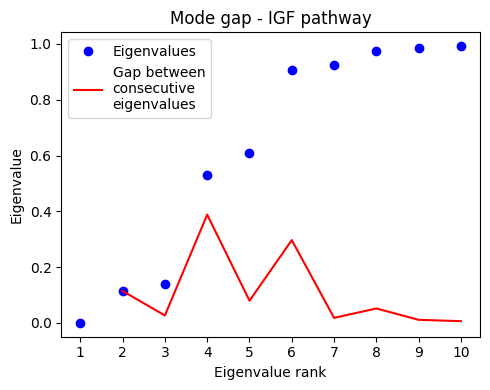

In [19]:
ri.pl.plot_mode_gap(adata, 'IGF', savefig=False, showfig=True)

The expression patterns of IGF ligands and receptors in these IGF CCC modes can be visualized via violin plots, and cell membership can be visualized in UMAP coordinate space:

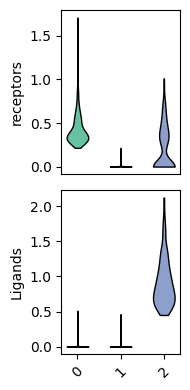

In [20]:
ri.pl.mode_violin(adata, 'IGF_modes', savefig=False, showfig=True)

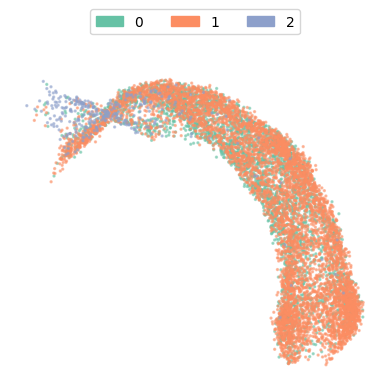

In [21]:
ri.pl.scatter2D(adata, 'IGF_modes', savefig=False, showfig=True)

Based on the expression of ligands and receptors, we rename the 3 IGF communication modes - this step is optional.

In [22]:
ri.tl.rename_modes(adata, 'IGF', {0: 'Receiver', 1: 'Inactive', 2: 'Sender/Receiver'})

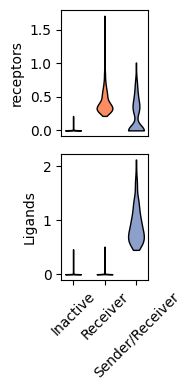

In [23]:
ri.pl.mode_violin(adata, 'IGF_modes', savefig=False, showfig=True)

The CCC heterogeneity score quantifies how heterogeneous each cell type is. In this case, all cell types pass the perumattion test (see asterisks), implying that all cell types are mixtures of cells in different IGF CCC signaling modes:

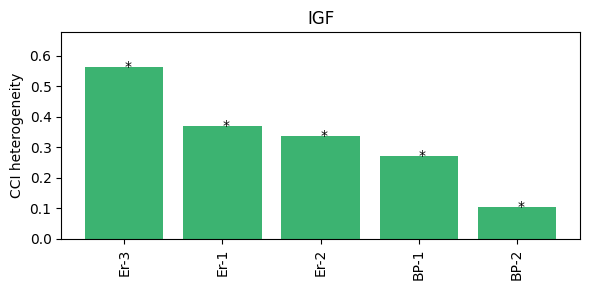

In [24]:
ri.pl.single_pathway_heterogeneity(adata, 'IGF', 'celltype', savefig=False, showfig=True)

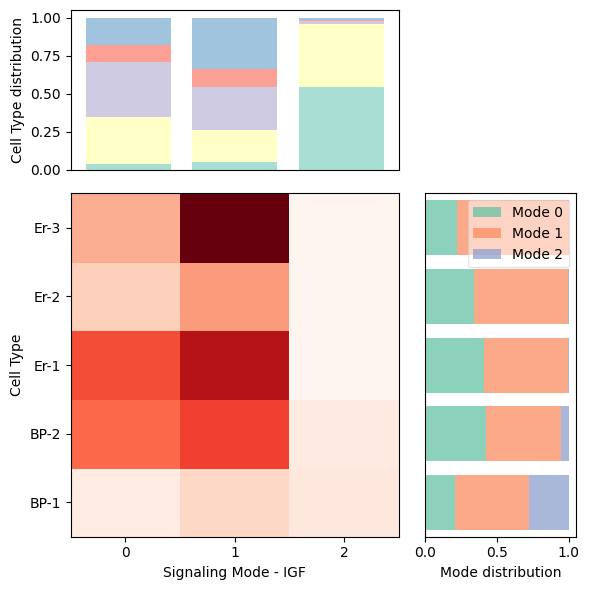

In [25]:
ri.pl.heatmap_one_pathway(adata, 'IGF', 'celltype', savefig=False, showfig=True)

The relation between cell types and IGF CCC signaling modes can be furhter visualized via barplots and alluvial diagram:

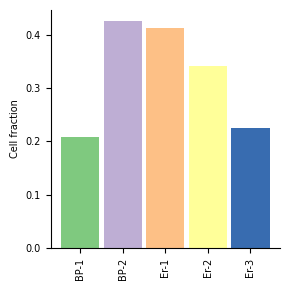

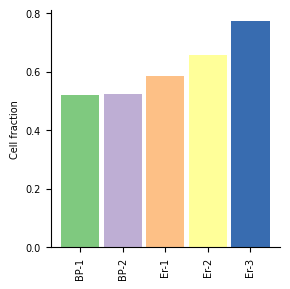

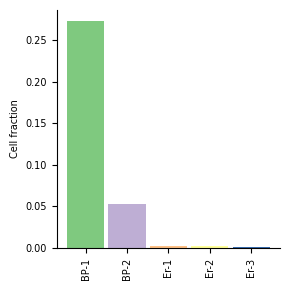

In [26]:
ri.pl.mode_composition(adata, 'celltype', 'IGF', 0, rename_states=['BP-1', 'BP-2', 'Er-1', 'Er-2', 'Er-3'], savefig=False, showfig=True)
ri.pl.mode_composition(adata, 'celltype', 'IGF', 1, rename_states=['BP-1', 'BP-2', 'Er-1', 'Er-2', 'Er-3'], savefig=False, showfig=True)
ri.pl.mode_composition(adata, 'celltype', 'IGF', 2, rename_states=['BP-1', 'BP-2', 'Er-1', 'Er-2', 'Er-3'], savefig=False, showfig=True)

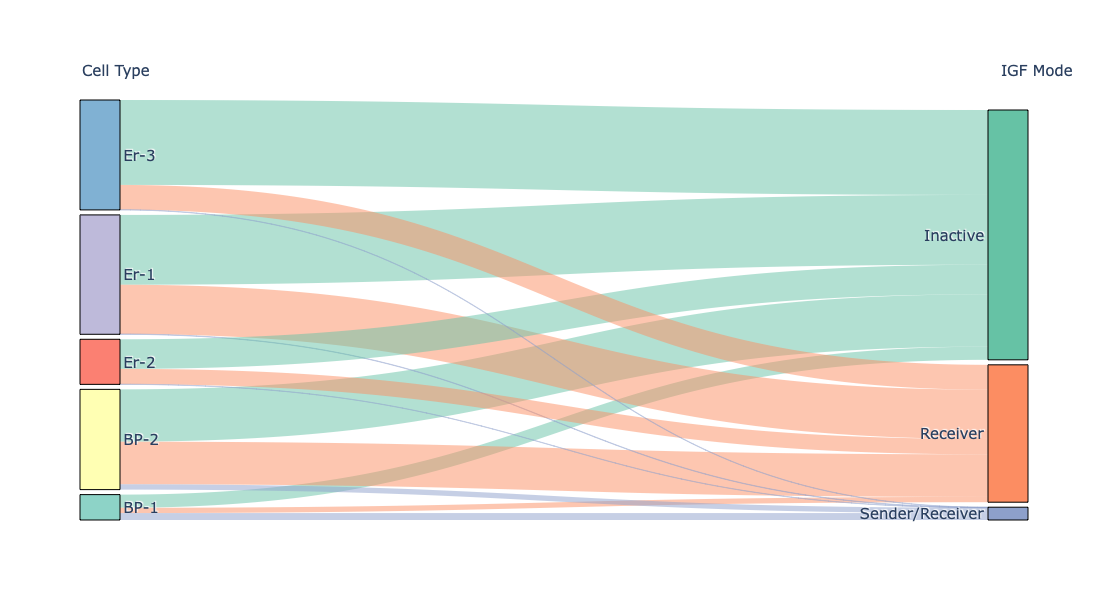

In [27]:
ri.pl.alluvial_onepath(adata, 'IGF', 'celltype', savefig=False, showfig=True)

Finally, we compute a communication matrix for IGF at CCC signaling mode resolution. This calculation can be performed based exclusively on the expression of ligands and receptors, or by also considering downstream targets of the signaling. In this case, we input a custom-made geneset of IGF targets:

In [31]:
igf = ['CSNK2A1', 'ELK1', 'FOS', 'GRB2', 'HRAS', 'IRS1', 'JUN', 'MAP2K1', 'MAPK3', 'MAPK8', 'PIK3CA', 'PIK3CG',
           'PIK3R1', 'PTPN11', 'RAF1', 'RASA1', 'SHC1', 'SOS1', 'SRF']
igf = [string.capwords(s) for s in igf]
ri.tl.import_database(adata, ['IGF'], species='mouse', unspliced=True, input_target={'IGF': igf})

In [32]:
ri.tl.compute_ccc_matrix(adata, 'IGF', key='celltype', include_target=True, conversion=True,
                             model='mass_action', min_cells=10)

The CCC matrix can be finally visualized as a chord diagram:

In [33]:
ri.pl.chord_diagram(adata, 'IGF')

[28-04-2026 15:27:23] [d3blocks.d3blocks] [INFO] Cleaning edge_properties and config parameters..
[28-04-2026 15:27:23] [d3blocks.d3blocks] [INFO] Cleaning edge_properties and config parameters..
[28-04-2026 15:27:23] [d3blocks.d3blocks] [INFO] Initializing [Chord]
[28-04-2026 15:27:23] [d3blocks.d3blocks] [INFO] Create directory: [%s]
[28-04-2026 15:27:23] [d3blocks.d3blocks] [INFO] filepath is set to [/var/folders/h8/221dz5dn3t7fnjtc80l_3p7c0000gn/T/d3blocks/chord.html]
[28-04-2026 15:27:23] [d3blocks.d3blocks] [INFO] Convert to DataFrame.
[28-04-2026 15:27:23] [d3blocks.d3blocks] [INFO] Node properties are set.
[28-04-2026 15:27:23] [d3blocks.d3blocks] [INFO] Set edge-opacity based on the [source] node-opacity.
[28-04-2026 15:27:23] [d3blocks.d3blocks] [INFO] Set edge-colors based on the [source] node-color.
[28-04-2026 15:27:23] [d3blocks.d3blocks] [INFO] Edge properties are set.
[28-04-2026 15:27:23] [d3blocks.d3blocks] [INFO] File not found: [file:////var/folders/h8/221dz5dn3t7fn

### 3-Visualize communication modes along RNA velocity 

The IGF CCC signaling modes can be further visualized together with RNA velocity transition trajectories - if available in the dataset:

In [34]:
scv.tl.velocity(adata, mode='stochastic')
scv.tl.velocity_graph(adata)

computing velocities
    finished (0:00:01) --> added 
    'velocity', velocity vectors for each individual cell (adata.layers)
computing velocity graph (using 1/8 cores)


  0%|          | 0/9815 [00:00<?, ?cells/s]

    finished (0:00:07) --> added 
    'velocity_graph', sparse matrix with cosine correlations (adata.uns)


computing velocity embedding
    finished (0:00:00) --> added
    'velocity_umap', embedded velocity vectors (adata.obsm)


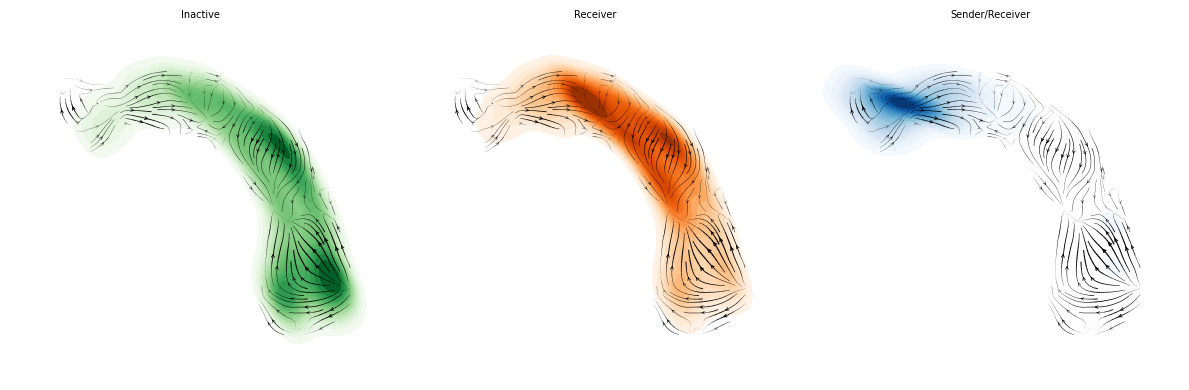

In [35]:
ri.pl.plot_maps(adata, 'IGF', savefig=False, showfig=True)

### 4-Identification of trends across CCC pathways

Now, we extend the analysis to several CCC pathways. First, the all_path_sim() function is run on the top 10 pathways. This can be easily done by setting the argument *pathways_to_use* to an integer rather than the name of a specific CCC pathway.

In [36]:
ri.tl.all_path_sim(adata, 'celltype', method='expression', pathways_to_use=10, target=False, human=False, neighbor_average=True, print_info=False)

['MK', 'MPZ', 'FGF', 'VEGF', 'JAM', 'IGF', 'PECAM1', 'AGRN', 'ANGPT', 'SPP1']
Analyzing the MK pathway...
running clustering
finished sim_mat for MK, starting spectral analysis

running consensus
Analyzing the MPZ pathway...
running clustering
finished sim_mat for MPZ, starting spectral analysis

running consensus
Analyzing the FGF pathway...
running clustering
finished sim_mat for FGF, starting spectral analysis

running consensus
Analyzing the VEGF pathway...
running clustering
finished sim_mat for VEGF, starting spectral analysis

running consensus
Analyzing the JAM pathway...
running clustering
finished sim_mat for JAM, starting spectral analysis

running consensus
Analyzing the IGF pathway...
running clustering
finished sim_mat for IGF, starting spectral analysis

running consensus
Analyzing the PECAM1 pathway...
running clustering
finished sim_mat for PECAM1, starting spectral analysis

running consensus
Analyzing the AGRN pathway...
running clustering
finished sim_mat for AGRN, 

Permutation test is also run automatically on all CCC pathways.

In [37]:
ri.tl.permutation_testing(adata, key='celltype')

Also compute mutual information between CCC pathways for later analysis:

In [42]:
ri.tl.pairwise_MI(adata)

Now, cells are reclustered based on their CCC signaling mode memebership to all considered CCC pathways, resulting in clusters of cell s with similar behavior when considering how signals are sent and received across all CCC pathways:

In [44]:
ri.tl.find_sign_patterns(adata, res=0.05)

Now, we can start to inspect trends across CCC pathways. First, the overall heterogeneity score of each cell type (over all CCC pathways) and each CCC pathway (over all cell types):

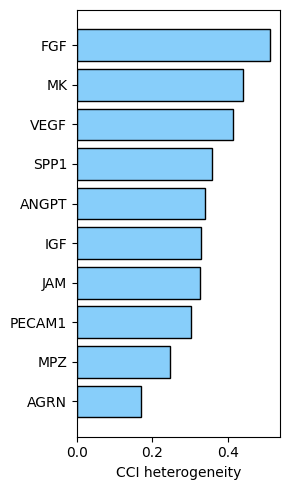

In [45]:
ri.pl.pathway_heterogeneity_summary(adata, key='celltype', savefig=False, showfig=True)

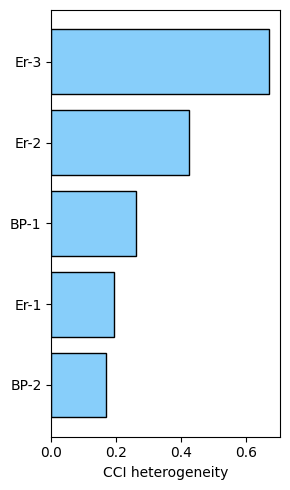

In [47]:
ri.pl.state_heterogeneity_summary(adata, 'celltype', savefig=False, showfig=True)

We can further inspect the correspondence between CCC signaling modes of two CCC pathways (IGF and VEGF)

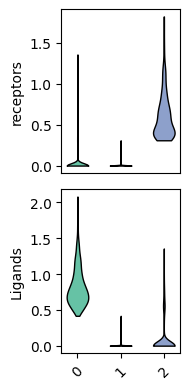

In [48]:
ri.pl.mode_violin(adata, 'VEGF_modes', savefig=False, showfig=True)

In [49]:
ri.tl.rename_modes(adata, 'VEGF', {0: 'Sender', 1: 'Inactive', 2: 'Receiver'})

In [50]:
ri.tl.rename_modes(adata, 'IGF', {0: 'Receiver', 1: 'Inactive', 2: 'Sender/Receiver'})

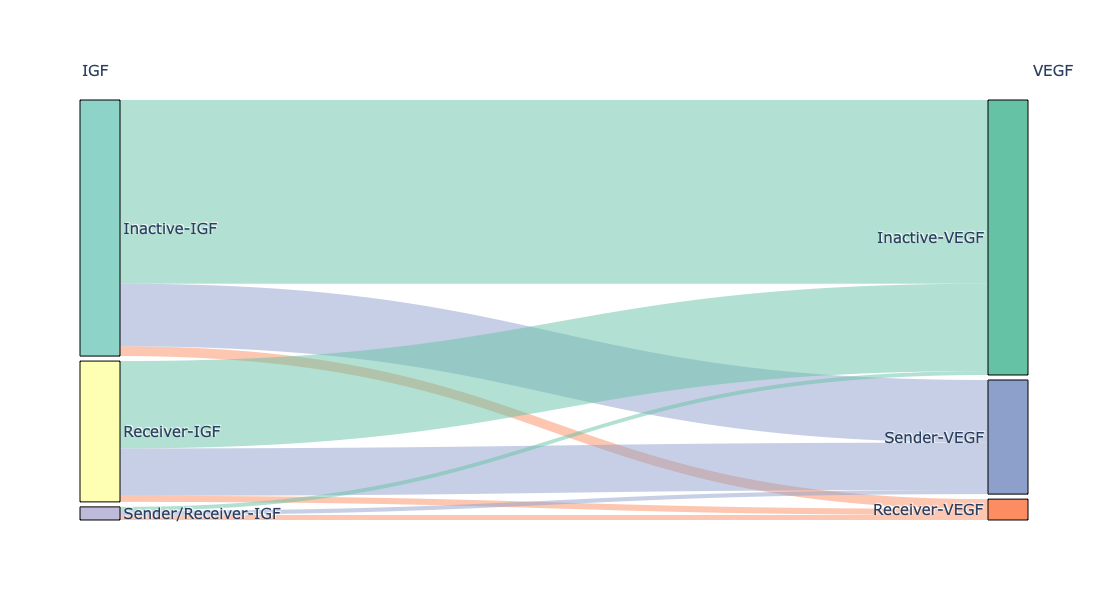

In [51]:
ri.pl.alluvial_twopath(adata, 'IGF', 'VEGF', savefig=False, showfig=True)

This approach can be generalized to evaluate the correspondence betweene ach pair of CCC pathways based on mutual information:

/Users/federicobocci/Desktop/commflow_project/ccc_project/scrich/plots/similarity.py:25: MatplotlibDeprecationWarning:

The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.

/Users/federicobocci/Desktop/commflow_project/ccc_project/scrich/plots/similarity.py:41: MatplotlibDeprecationWarning:

Getting the array from a PolyQuadMesh will return the full array in the future (uncompressed). To get this behavior now set the PolyQuadMesh with a 2D array .set_array(data2d).



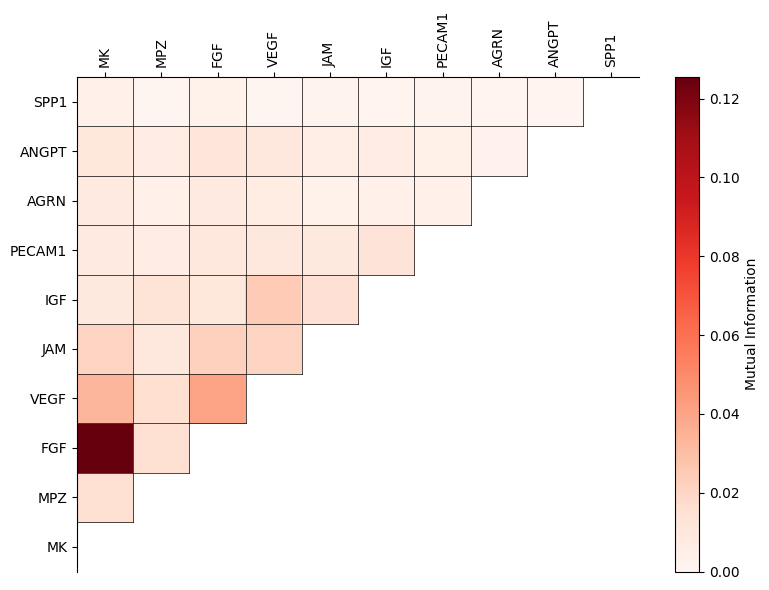

In [53]:
ri.pl.redundancy(adata, savefig=False, showfig=True)

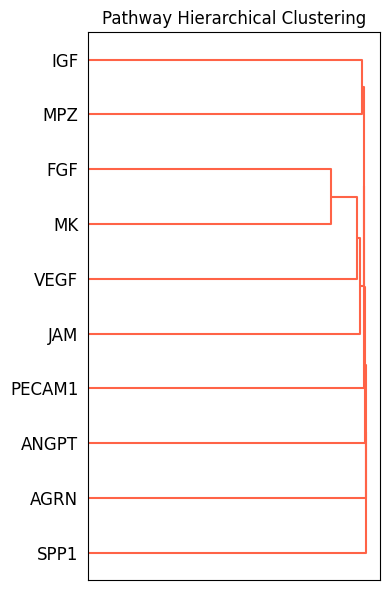

In [56]:
ri.pl.pathway_hierarchy(adata, savefig=False, showfig=True)

Finally, we can move from pairwise pathway comparison to global trands when evaluating all CCC pathways toggether. In this case, the *ri.tl.find_sign_patterns()* function identifies 12 global patterns of communication across many CCC pathways:

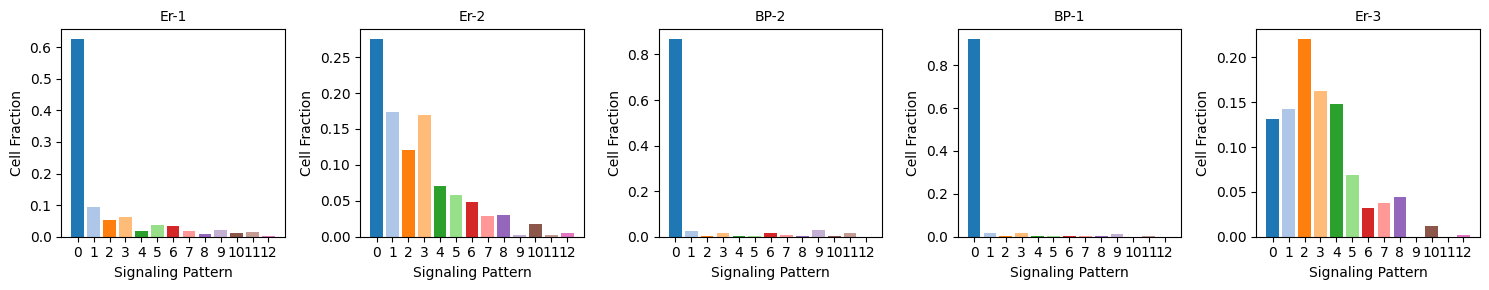

In [58]:
ri.pl.pattern_summary(adata, 'celltype', panel_per_row=5, savefig=False, showfig=True)

The correspondence between cell types and these CCC patterns can be inspected via alluvial plot" 

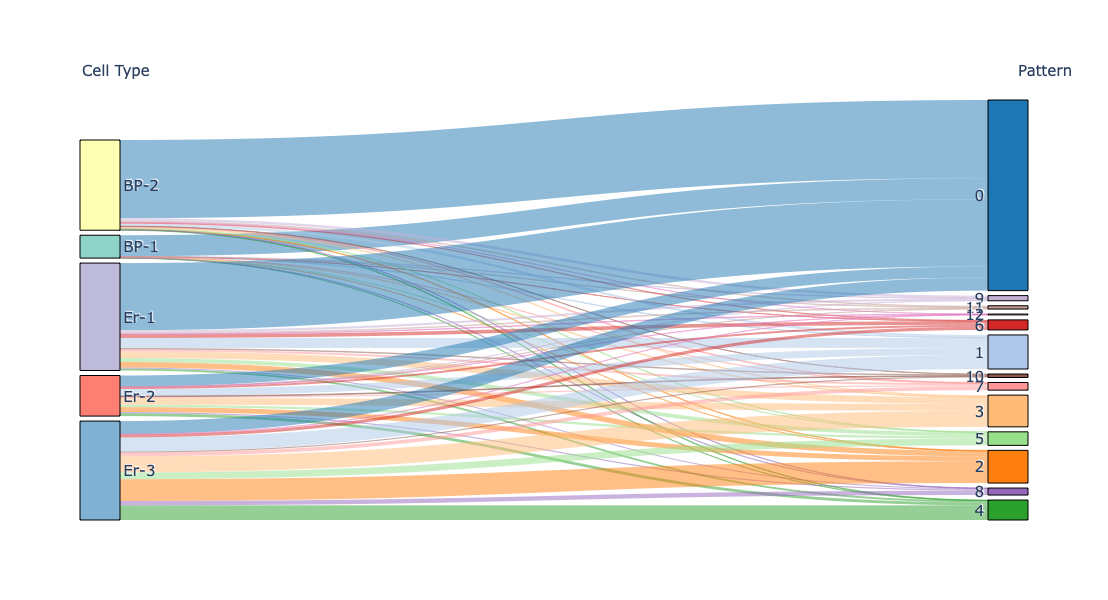

In [59]:
ri.pl.alluvial_pattern(adata, 'celltype', savefig=False, showfig=True)

Furthermore, the cell type representation and key ligands/receptors characterizing each CCC pattern can be identified:

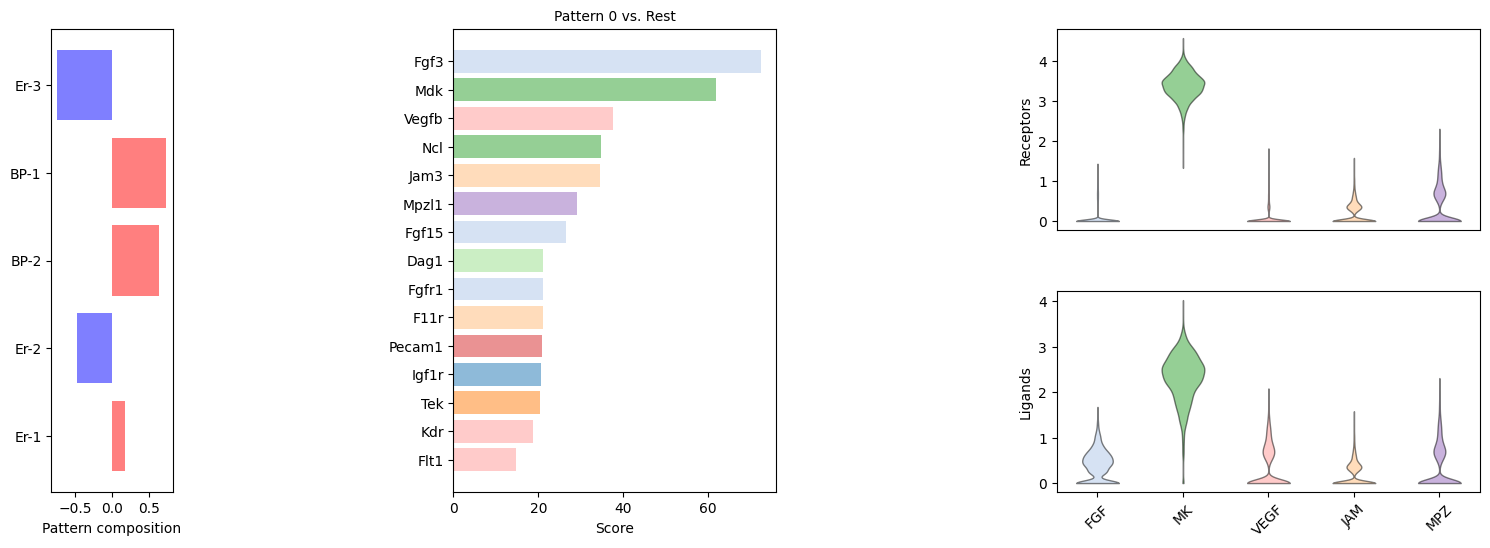

In [61]:
ri.pl.pattern(adata, 0, key='celltype', human=False, ntop=15, savefig=False, showfig=True)